# Global Superstore Sales Analysis
**End-to-end Python data analytics project**

## Objective
Analyze a Global Superstore order-level dataset to understand sales, profitability, product performance, customer segments, regional/market patterns, discounts, and shipping.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook / Google Colab.

## Dataset note
This notebook was prepared for the provided `Global-Superstore.csv` file. The source file uses a legacy text encoding, so it is loaded with `encoding="latin1"`. It also contains mostly-empty auxiliary columns; those are reviewed and removed during cleaning.

## Attribution
If this dataset was supplied by an instructor or downloaded from another repository, cite that exact source here and follow its data license/permission terms. Do not claim ownership of the original dataset. Describe your own analysis improvements in the README.

## 1. Import libraries

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 2. Load the dataset

In [ ]:
import pandas as pd
DATA_PATH = "/content/Global-Superstore.csv"

# This file is encoded as a legacy single-byte text file, not UTF-8.
df_raw = pd.read_csv(DATA_PATH, encoding="latin1", low_memory=False)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 51,290
Columns: 28


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Unnamed: 24,Unnamed: 25,Sales_10%,Unnamed: 27
0,32298,CA-2012-124891,7/31/2012,7/31/2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,United States,"10,024.00",US,East,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,"2,309.65",7,0.00,762.18,933.57,Critical,"3,071.83",9.00,"2,540.61",899.38
1,26341,IN-2013-77878,2/5/2013,2/7/2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,Australia,NaN,APAC,Oceania,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black","3,709.39",9,0.10,-288.76,923.63,Critical,"3,420.63",11.00,"4,080.33",-340.74
2,25330,IN-2013-71249,10/17/2013,10/18/2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,Australia,NaN,APAC,Oceania,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID","5,175.17",9,0.10,919.97,915.49,Medium,"6,095.14",11.00,"5,692.69","1,085.57"
3,13524,ES-2013-1579342,1/28/2013,1/30/2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,Germany,NaN,EU,Central,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless","2,892.51",5,0.10,-96.54,910.16,Medium,"2,795.97",7.00,"3,181.76",-113.92
4,47221,SG-2013-4320,11/5/2013,11/6/2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,Senegal,NaN,Africa,Africa,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed","2,832.96",8,0.00,311.52,903.04,Critical,"3,144.48",10.00,"3,116.26",367.59


## 3. Initial data inspection

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nDuplicate rows:", df.duplicated().sum())

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)
display(df.describe(include="all").T)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority', 'Unnamed: 24', 'Unnamed: 25', 'Sales_10%', 'Unnamed: 27']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non

,missing_count,missing_percent
Unnamed: 25,51274,99.97
Sales_10%,51274,99.97
Unnamed: 27,51274,99.97
Unnamed: 24,51268,99.96
Postal Code,41296,80.51
Ship Mode,0,0.00
Customer Name,0,0.00
Customer ID,0,0.00
Ship Date,0,0.00
Row ID,0,0.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,"51,290.00",NaN,NaN,NaN,"25,645.50","14,806.29",1.00,"12,823.25","25,645.50","38,467.75","51,290.00"
Order ID,51290,25035,CA-2014-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,51290,1430,6/18/2014,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,51290,1464,11/22/2014,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,51290,4,Standard Class,30775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,51290,1590,PO-18850,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,51290,795,Muhammed Yedwab,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,51290,3,Consumer,26518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,51290,3636,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,51290,1094,California,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data cleaning and preprocessing

- Normalize column names.
- Remove completely empty columns and auxiliary columns that are overwhelmingly empty.
- Parse order and ship dates.
- Convert numeric measures to numeric types.
- Remove exact duplicate rows, if any.
- Keep missing postal codes as missing: postal codes are not available for many international records, so filling them with fabricated values would be misleading.

In [ ]:
def normalize_name(column):
    return (
        str(column).strip().lower()
        .replace(" ", "_").replace("-", "_").replace("/", "_")
    )

df.columns = [normalize_name(c) for c in df.columns]

# Remove columns that contain no useful data.
all_empty = [c for c in df.columns if df[c].isna().all()]
df.drop(columns=all_empty, inplace=True)

# Some exports contain stray unnamed/helper columns with almost all values missing.
mostly_empty = [
    c for c in df.columns
    if c.startswith("unnamed") and df[c].isna().mean() >= 0.90
]
df.drop(columns=mostly_empty, inplace=True)

# Drop the mostly-empty derived/helper column if present; it is not needed for core analysis.
if "sales_10%" in df.columns and df["sales_10%"].isna().mean() >= 0.90:
    df.drop(columns=["sales_10%"], inplace=True)

for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

for col in ["row_id", "postal_code", "sales", "quantity", "discount", "profit", "shipping_cost"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

rows_before = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = rows_before - len(df)

print("Removed all-empty columns:", all_empty)
print("Removed mostly-empty helper columns:", mostly_empty)
print("Exact duplicate rows removed:", duplicates_removed)
print("Cleaned shape:", df.shape)
display(df.head())

Removed all-empty columns: []
Removed mostly-empty helper columns: ['unnamed:_24', 'unnamed:_25', 'unnamed:_27']
Exact duplicate rows removed: 0
Cleaned shape: (51290, 24)


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,country,postal_code,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,United States,"10,024.00",US,East,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,"2,309.65",7,0.00,762.18,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,Australia,NaN,APAC,Oceania,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black","3,709.39",9,0.10,-288.76,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,Australia,NaN,APAC,Oceania,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID","5,175.17",9,0.10,919.97,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,Germany,NaN,EU,Central,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless","2,892.51",5,0.10,-96.54,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,Senegal,NaN,Africa,Africa,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed","2,832.96",8,0.00,311.52,903.04,Critical


## 5. Data quality after cleaning

In [ ]:
post_cleaning_missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(post_cleaning_missing)

if "order_date" in df.columns:
    print("Invalid/missing order dates:", df["order_date"].isna().sum())
if "ship_date" in df.columns:
    print("Invalid/missing ship dates:", df["ship_date"].isna().sum())

# Negative profit can be a real business outcome, so do not delete it as an error.
if "profit" in df.columns:
    print("Rows with negative profit:", int((df["profit"] < 0).sum()))

,missing_count,missing_percent
postal_code,41296,80.51
row_id,0,0.00
order_date,0,0.00
order_id,0,0.00
ship_mode,0,0.00
customer_id,0,0.00
customer_name,0,0.00
ship_date,0,0.00
segment,0,0.00
city,0,0.00


Invalid/missing order dates: 0
Invalid/missing ship dates: 0
Rows with negative profit: 12544


## 6. Feature engineering

In [ ]:
if "order_date" in df.columns:
    df["order_year"] = df["order_date"].dt.year
    df["order_month"] = df["order_date"].dt.month
    df["order_year_month"] = df["order_date"].dt.to_period("M").astype(str)

if "order_date" in df.columns and "ship_date" in df.columns:
    df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days

if "sales" in df.columns and "profit" in df.columns:
    df["profit_margin_pct"] = np.where(
        df["sales"] != 0, df["profit"] / df["sales"] * 100, np.nan
    )

display(df.head())

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,country,postal_code,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,order_year,order_month,order_year_month,shipping_days,profit_margin_pct
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,United States,"10,024.00",US,East,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,"2,309.65",7,0.00,762.18,933.57,Critical,2012,7,2012-07,0,33.00
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,Australia,NaN,APAC,Oceania,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black","3,709.39",9,0.10,-288.76,923.63,Critical,2013,2,2013-02,2,-7.78
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,Australia,NaN,APAC,Oceania,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID","5,175.17",9,0.10,919.97,915.49,Medium,2013,10,2013-10,1,17.78
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,Germany,NaN,EU,Central,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless","2,892.51",5,0.10,-96.54,910.16,Medium,2013,1,2013-01,2,-3.34
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,Senegal,NaN,Africa,Africa,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed","2,832.96",8,0.00,311.52,903.04,Critical,2013,11,2013-11,1,11.00


## 7. Key performance indicators (KPIs)

In [ ]:
kpis = {}
if "sales" in df.columns:
    kpis["Total Sales"] = df["sales"].sum()
if "profit" in df.columns:
    kpis["Total Profit"] = df["profit"].sum()
if "quantity" in df.columns:
    kpis["Units Sold"] = df["quantity"].sum()
if "order_id" in df.columns:
    kpis["Unique Orders"] = df["order_id"].nunique()
if "customer_id" in df.columns:
    kpis["Unique Customers"] = df["customer_id"].nunique()
if "product_id" in df.columns:
    kpis["Unique Products"] = df["product_id"].nunique()
if "sales" in df.columns and "profit" in df.columns and df["sales"].sum() != 0:
    kpis["Overall Profit Margin (%)"] = df["profit"].sum() / df["sales"].sum() * 100

display(pd.DataFrame({"Metric": list(kpis.keys()), "Value": list(kpis.values())}))

,Metric,Value
0,Total Sales,"12,642,501.91"
1,Total Profit,"1,467,457.29"
2,Units Sold,"178,312.00"
3,Unique Orders,"25,035.00"
4,Unique Customers,"1,590.00"
5,Unique Products,"10,292.00"
6,Overall Profit Margin (%),11.61


## 8. Sales and profit by category

,total_sales
category,
Technology,"4,744,557.50"
Furniture,"4,110,874.19"
Office Supplies,"3,787,070.23"


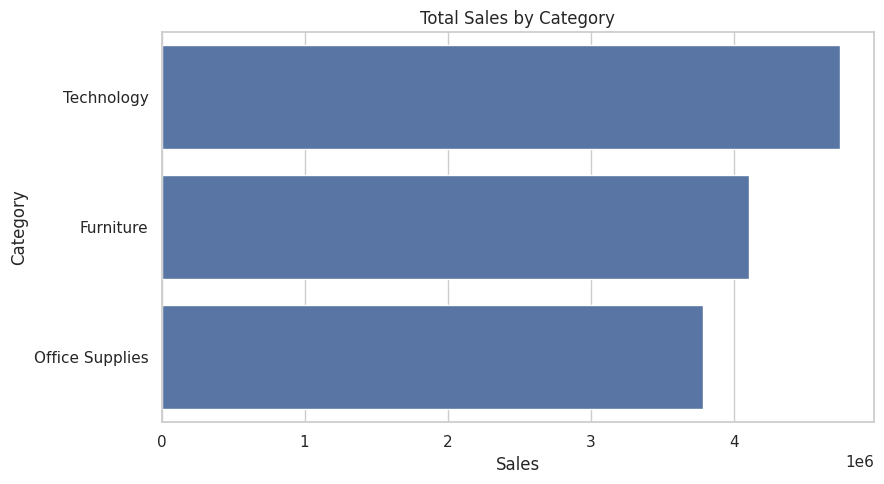

,total_profit
category,
Technology,"663,778.73"
Office Supplies,"518,473.83"
Furniture,"285,204.72"


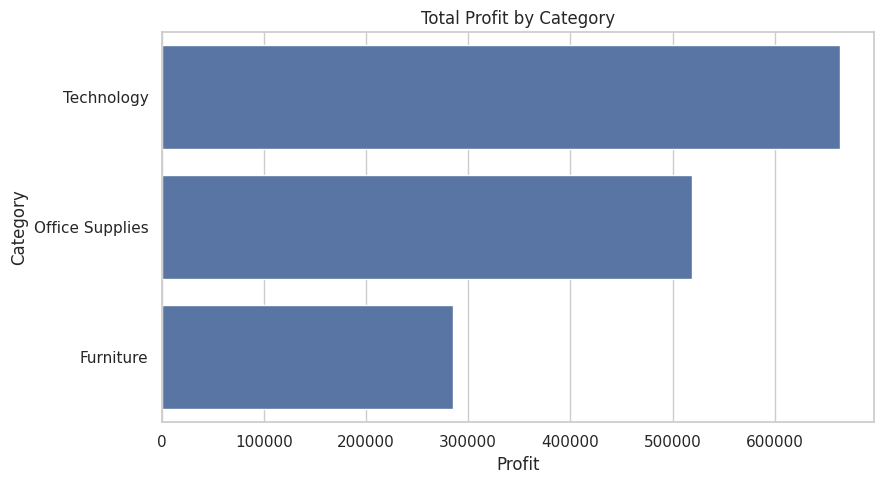

In [ ]:
if "category" in df.columns and "sales" in df.columns:
    sales_by_category = df.groupby("category")["sales"].sum().sort_values(ascending=False)
    display(sales_by_category.to_frame("total_sales"))
    plt.figure(figsize=(9, 5))
    sns.barplot(x=sales_by_category.values, y=sales_by_category.index)
    plt.title("Total Sales by Category")
    plt.xlabel("Sales")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.savefig(
    "../visualizations/category_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


if "category" in df.columns and "profit" in df.columns:
    profit_by_category = df.groupby("category")["profit"].sum().sort_values(ascending=False)
    display(profit_by_category.to_frame("total_profit"))
    plt.figure(figsize=(9, 5))
    sns.barplot(x=profit_by_category.values, y=profit_by_category.index)
    plt.title("Total Profit by Category")
    plt.xlabel("Profit")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

## 9. Monthly sales trend

,monthly_sales
order_date,
2011-01-01,"98,898.49"
2011-02-01,"91,152.16"
2011-03-01,"145,729.37"
2011-04-01,"116,915.76"
2011-05-01,"146,747.84"
2011-06-01,"215,207.38"
2011-07-01,"115,510.42"
2011-08-01,"207,581.49"
2011-09-01,"290,214.46"


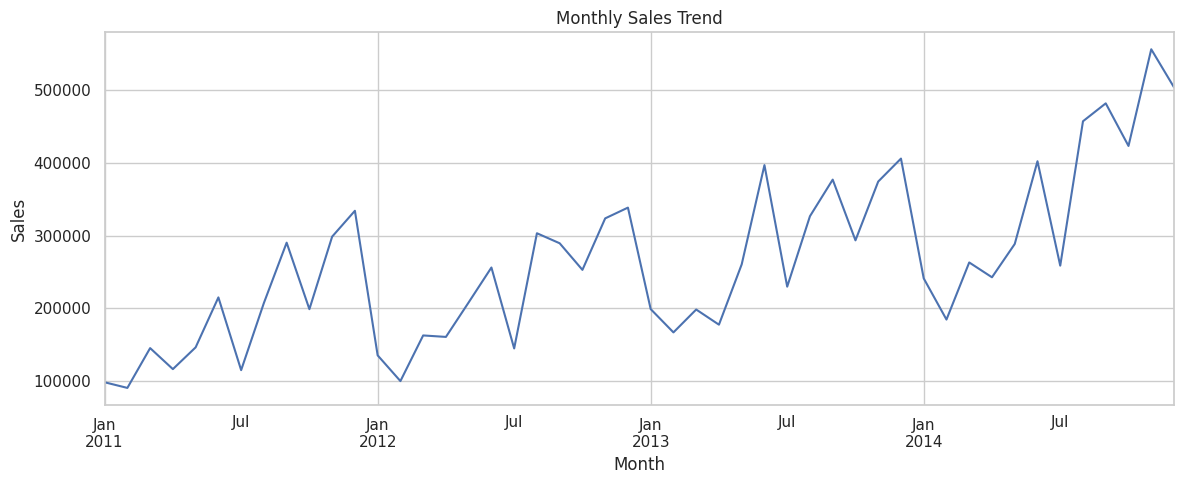

In [ ]:
if {"order_date", "sales"}.issubset(df.columns):
    monthly_sales = (
        df.dropna(subset=["order_date"])
          .set_index("order_date")["sales"]
          .resample("MS").sum()
    )
    display(monthly_sales.to_frame("monthly_sales").head(12))
    plt.figure(figsize=(12, 5))
    monthly_sales.plot()
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Sales")
    plt.tight_layout()
    plt.show()

## 10. Market and regional performance

,total_sales
market,
APAC,"3,585,744.13"
EU,"2,938,089.06"
US,"2,297,200.86"
LATAM,"2,164,605.17"
EMEA,"806,161.31"
Africa,"783,773.21"
Canada,"66,928.17"


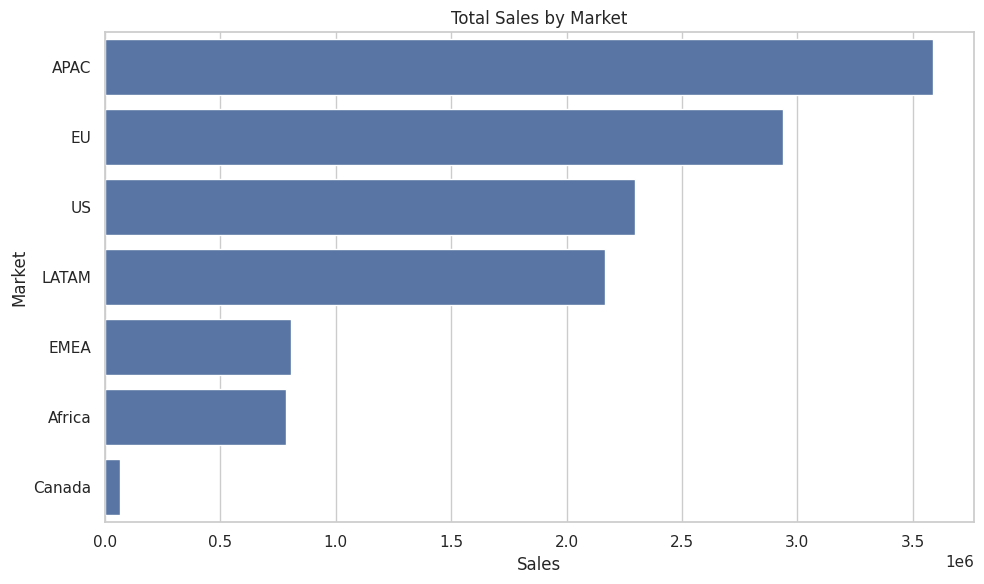

,total_profit
market,
Canada,"17,817.39"
EMEA,"43,897.97"
Africa,"88,871.63"
LATAM,"221,643.49"
US,"286,397.02"
EU,"372,829.74"
APAC,"436,000.05"


,total_sales
region,
Central,"2,822,302.52"
South,"1,600,907.04"
North,"1,248,165.60"
Oceania,"1,100,184.61"
Southeast Asia,"884,423.17"
North Asia,"848,309.78"
EMEA,"806,161.31"
Africa,"783,773.21"
Central Asia,"752,826.57"


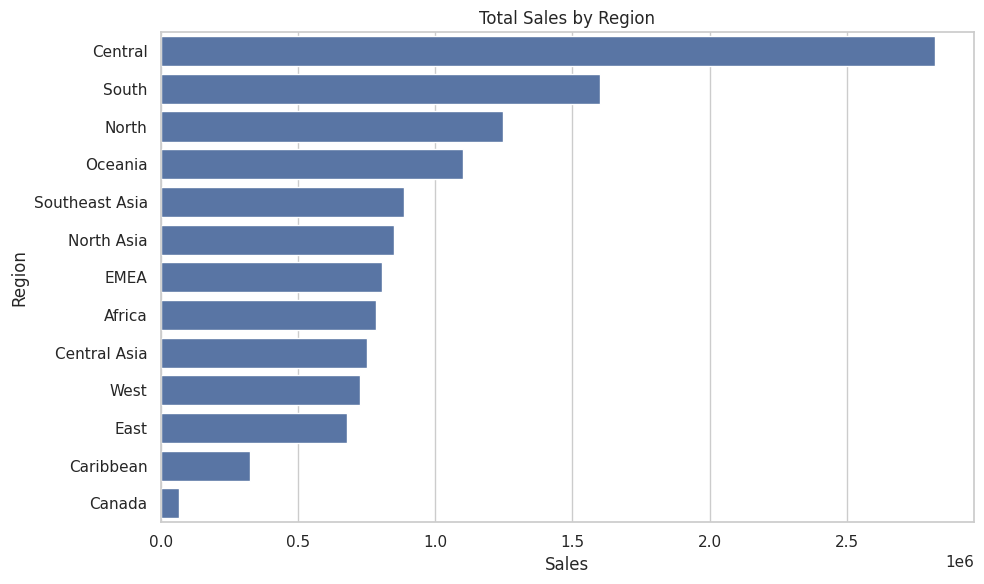

,total_profit
region,
Canada,"17,817.39"
Southeast Asia,"17,852.33"
Caribbean,"34,571.32"
EMEA,"43,897.97"
Africa,"88,871.63"
East,"91,522.78"
West,"108,418.45"
Oceania,"120,089.11"
Central Asia,"132,480.19"


In [ ]:
for dimension in ["market", "region"]:
    if dimension in df.columns and "sales" in df.columns:
        summary = df.groupby(dimension)["sales"].sum().sort_values(ascending=False)
        display(summary.to_frame("total_sales"))
        plt.figure(figsize=(10, 6))
        sns.barplot(x=summary.values, y=summary.index)
        plt.title(f"Total Sales by {dimension.title()}")
        plt.xlabel("Sales")
        plt.ylabel(dimension.title())
        plt.tight_layout()
        plt.show()

    if dimension in df.columns and "profit" in df.columns:
        display(df.groupby(dimension)["profit"].sum().sort_values().to_frame("total_profit"))

## 11. Top products and sub-categories

,total_sales
product_name,
"Apple Smart Phone, Full Size","86,935.78"
"Cisco Smart Phone, Full Size","76,441.53"
"Motorola Smart Phone, Full Size","73,156.30"
"Nokia Smart Phone, Full Size","71,904.56"
Canon imageCLASS 2200 Advanced Copier,"61,599.82"
"Hon Executive Leather Armchair, Adjustable","58,193.48"
"Office Star Executive Leather Armchair, Adjustable","50,661.68"
"Harbour Creations Executive Leather Armchair, Adjustable","50,121.52"
"Samsung Smart Phone, Cordless","48,653.46"


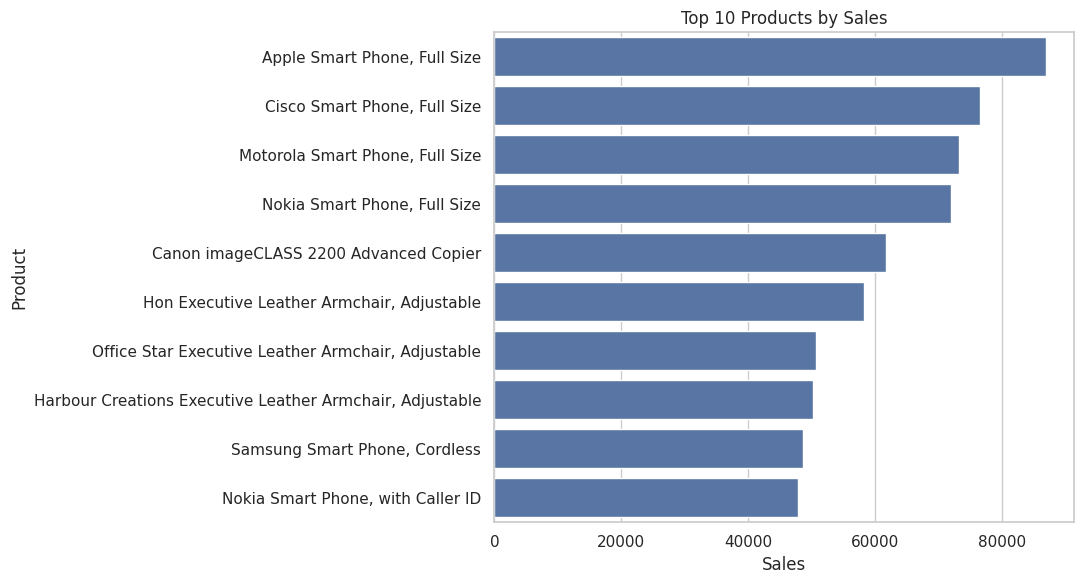

,total_profit
sub_category,
Tables,"-64,083.39"
Fasteners,"11,525.42"
Labels,"15,010.51"
Supplies,"22,583.26"
Envelopes,"29,601.12"
Furnishings,"46,967.43"
Art,"57,953.91"
Machines,"58,867.87"
Paper,"59,207.68"


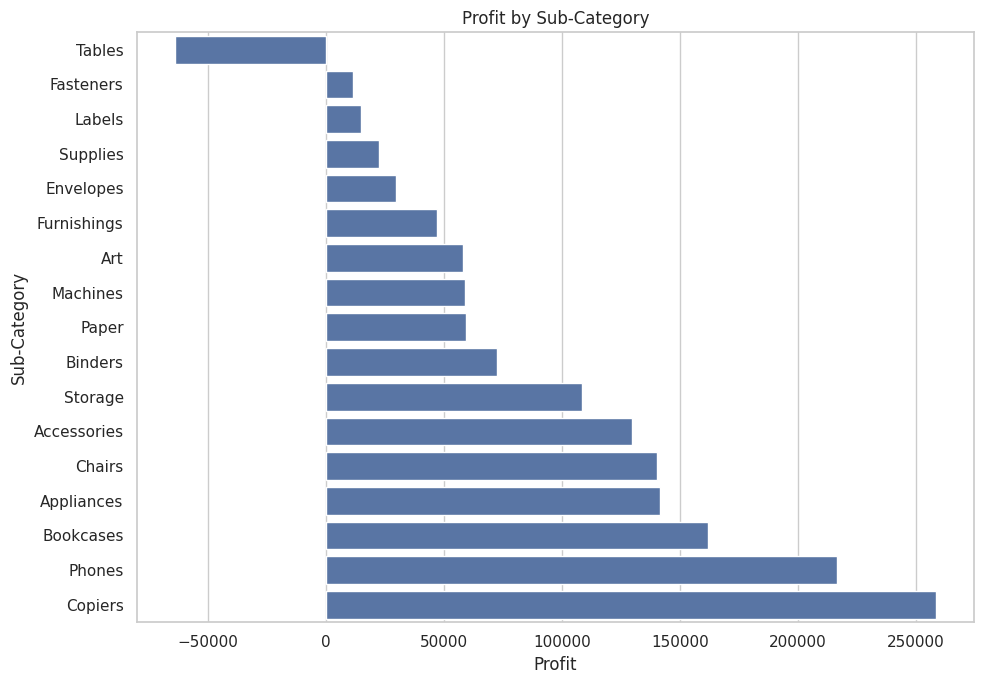

In [ ]:
if "product_name" in df.columns and "sales" in df.columns:
    top_products = df.groupby("product_name")["sales"].sum().sort_values(ascending=False).head(10)
    display(top_products.to_frame("total_sales"))
    plt.figure(figsize=(11, 6))
    sns.barplot(x=top_products.values, y=top_products.index)
    plt.title("Top 10 Products by Sales")
    plt.xlabel("Sales")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

if "sub_category" in df.columns and "profit" in df.columns:
    subcategory_profit = df.groupby("sub_category")["profit"].sum().sort_values()
    display(subcategory_profit.to_frame("total_profit"))
    plt.figure(figsize=(10, 7))
    sns.barplot(x=subcategory_profit.values, y=subcategory_profit.index)
    plt.title("Profit by Sub-Category")
    plt.xlabel("Profit")
    plt.ylabel("Sub-Category")
    plt.tight_layout()
    plt.show()

## 12. Customer segment analysis

,total_sales
segment,
Consumer,"6,507,949.42"
Corporate,"3,824,697.52"
Home Office,"2,309,854.97"


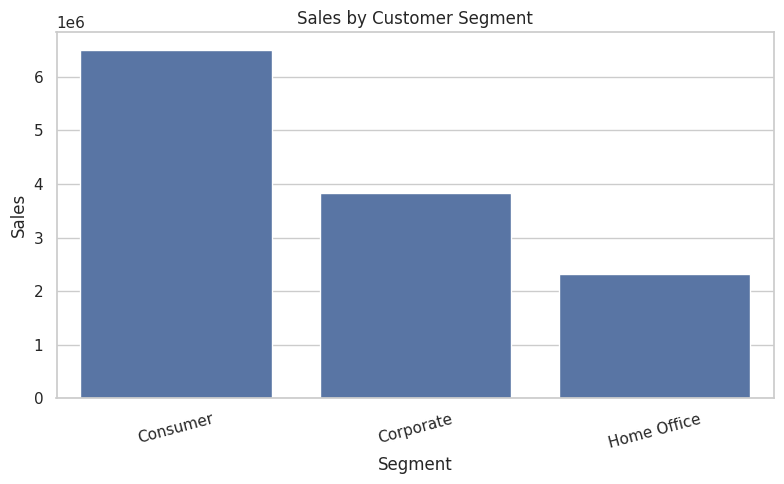

,total_profit
segment,
Consumer,"749,239.78"
Corporate,"441,208.33"
Home Office,"277,009.18"


In [ ]:
if "segment" in df.columns and "sales" in df.columns:
    segment_sales = df.groupby("segment")["sales"].sum().sort_values(ascending=False)
    display(segment_sales.to_frame("total_sales"))
    plt.figure(figsize=(8, 5))
    sns.barplot(x=segment_sales.index, y=segment_sales.values)
    plt.title("Sales by Customer Segment")
    plt.xlabel("Segment")
    plt.ylabel("Sales")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

if "segment" in df.columns and "profit" in df.columns:
    display(df.groupby("segment")["profit"].sum().sort_values(ascending=False).to_frame("total_profit"))

## 13. Discount versus profit

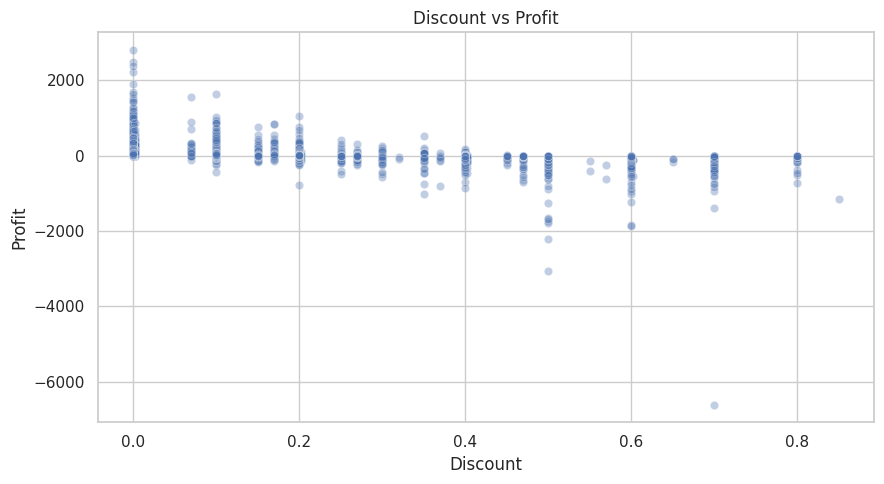

,row_count,total_profit,average_profit
discount,,,
0.00,29009,"1,770,695.27",61.04
0.00,461,"57,976.58",125.76
0.07,150,"21,148.50",140.99
0.10,4068,"259,064.18",63.68
0.15,541,"27,375.90",50.60
0.17,735,"28,163.07",38.32
0.20,4998,"117,715.87",23.55
0.20,41,-595.27,-14.52
0.25,198,800.59,4.04


In [ ]:
if {"discount", "profit"}.issubset(df.columns):
    plot_data = df[["discount", "profit"]].dropna()
    if len(plot_data) > 10000:
        plot_data = plot_data.sample(10000, random_state=42)
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=plot_data, x="discount", y="profit", alpha=0.35)
    plt.title("Discount vs Profit")
    plt.xlabel("Discount")
    plt.ylabel("Profit")
    plt.tight_layout()
    plt.show()

    discount_summary = df.groupby("discount").agg(
        row_count=("profit", "size"),
        total_profit=("profit", "sum"),
        average_profit=("profit", "mean")
    ).sort_index()
    display(discount_summary)

## 14. Shipping analysis

In [ ]:
if "shipping_days" in df.columns:
    print("Rows with negative shipping duration:", int((df["shipping_days"] < 0).sum()))
    display(df["shipping_days"].describe().to_frame("shipping_days_summary"))
    if "ship_mode" in df.columns:
        display(
            df.groupby("ship_mode")["shipping_days"]
              .median().sort_values()
              .to_frame("median_shipping_days")
        )

Rows with negative shipping duration: 0


,shipping_days_summary
count,"51,290.00"
mean,3.97
std,1.73
min,0.00
25%,3.00
50%,4.00
75%,5.00
max,7.00


,median_shipping_days
ship_mode,
Same Day,0.00
First Class,2.00
Second Class,3.00
Standard Class,5.00


## 15. Generate data-driven draft insights

In [ ]:
insights = []

if "category" in df.columns and "sales" in df.columns:
    s = df.groupby("category")["sales"].sum().sort_values(ascending=False)
    if not s.empty:
        insights.append(f"Highest-sales category: {s.index[0]} (sales = {s.iloc[0]:,.2f}).")

if "category" in df.columns and "profit" in df.columns:
    p = df.groupby("category")["profit"].sum().sort_values(ascending=False)
    if not p.empty:
        insights.append(f"Highest-profit category: {p.index[0]} (profit = {p.iloc[0]:,.2f}).")

if "market" in df.columns and "sales" in df.columns:
    m = df.groupby("market")["sales"].sum().sort_values(ascending=False)
    if not m.empty:
        insights.append(f"Highest-sales market: {m.index[0]} (sales = {m.iloc[0]:,.2f}).")

if "region" in df.columns and "sales" in df.columns:
    r = df.groupby("region")["sales"].sum().sort_values(ascending=False)
    if not r.empty:
        insights.append(f"Highest-sales region: {r.index[0]} (sales = {r.iloc[0]:,.2f}).")

if "profit" in df.columns:
    insights.append(f"Records with negative profit: {(df['profit'] < 0).sum():,} of {len(df):,} rows.")

for i, insight in enumerate(insights, start=1):
    print(f"{i}. {insight}")

1. Highest-sales category: Technology (sales = 4,744,557.50).
2. Highest-profit category: Technology (profit = 663,778.73).
3. Highest-sales market: APAC (sales = 3,585,744.13).
4. Highest-sales region: Central (sales = 2,822,302.52).
5. Records with negative profit: 12,544 of 51,290 rows.


## 16. Export cleaned data

Only include the cleaned dataset in a public repository if the dataset's terms allow redistribution. If not, remove this export from the public repo and add instructions for obtaining the source data.

In [ ]:
cleaned_path = "Global-Superstore-Cleaned.csv"
df.to_csv(cleaned_path, index=False)
print("Saved:", cleaned_path)

Saved: Global-Superstore-Cleaned.csv


## 17. Conclusion and recommendations

Use the actual output above to write your final conclusions. Answer:
1. Which category earns the most sales and profit?
2. Which market and region perform best and worst?
3. What patterns appear in monthly sales?
4. Are higher discounts associated with lower profits in this dataset?
5. Which sub-categories show losses and deserve further investigation?
6. What limitations remain in the data?

Do not claim correlation proves causation. Explain that negative profit may represent real loss-making transactions and should not automatically be removed.